In [1]:
import os
os.chdir('/content')
CODE_DIR = 'pixel2style2pixel'

In [2]:
!git clone https://github.com/eladrich/pixel2style2pixel.git $CODE_DIR

Cloning into 'pixel2style2pixel'...
remote: Enumerating objects: 418, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 418 (delta 0), reused 2 (delta 0), pack-reused 414 (from 1)
Receiving objects: 100% (418/418), 92.94 MiB | 14.30 MiB/s, done.
Resolving deltas: 100% (147/147), done.


In [3]:
!wget https://github.com/ninja-build/ninja/releases/download/v1.8.2/ninja-linux.zip
!sudo unzip ninja-linux.zip -d /usr/local/bin/
!sudo update-alternatives --install /usr/bin/ninja ninja /usr/local/bin/ninja 1 --force

--2026-02-22 11:06:35--  https://github.com/ninja-build/ninja/releases/download/v1.8.2/ninja-linux.zip
Resolving github.com (github.com)... 20.205.243.166
Connecting to github.com (github.com)|20.205.243.166|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/1335132/d2f252e2-9801-11e7-9fbf-bc7b4e4b5c83?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-02-22T11%3A42%3A58Z&rscd=attachment%3B+filename%3Dninja-linux.zip&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-02-22T10%3A42%3A57Z&ske=2026-02-22T11%3A42%3A58Z&sks=b&skv=2018-11-09&sig=l6NS9TbJnKsvobQ3xoJ7TM52U%2FDK2ro6lpwoIRJnhdA%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwiYXVkIjoicmVsZWFzZS1hc3NldHMuZ2l0aHVidXNlcmNvbnRlbnQuY29tIiwia2V5Ijoia2V5MSIsImV4cCI6MTc3MTc1ODY5NSwibmJmIjoxNzcxNzU4Mzk1LCJwYXRoIjoicmVsZWFzZWFzc2V0cHJvZHVjdGlvbi5i

In [4]:
os.chdir(f'./{CODE_DIR}')

In [5]:
from argparse import Namespace
import time
import pprint
import numpy as np
from PIL import Image
import torch
import torchvision.transforms as transforms

# from datasets import augmentations
from utils.common import tensor2im, log_input_image
from models.psp import pSp

In [6]:
!ls

cog.yaml  datasets	       environment  models     predict.py  training
configs   docs		       LICENSE	    notebooks  README.md   utils
criteria  download-weights.sh  licenses     options    scripts


## Step 1: Select Experiment Type

In [7]:
#@title Select which experiment you wish to perform inference on: { run: "auto" }
experiment_type = 'ffhq_encode' #@param ['ffhq_encode', 'ffhq_frontalize', 'celebs_sketch_to_face', 'celebs_seg_to_face', 'celebs_super_resolution', 'toonify']

## Step 2: Download Pretrained Models

In [8]:
def get_download_model_command(file_id, file_name):
    """ Get wget download command for downloading the desired model and save to directory ../pretrained_models. """
    current_directory = os.getcwd()
    save_path = os.path.join(os.path.dirname(current_directory), CODE_DIR, "pretrained_models")
    if not os.path.exists(save_path):
        os.makedirs(save_path)
    url = r"""wget --load-cookies /tmp/cookies.txt "https://docs.google.com/uc?export=download&confirm=$(wget --quiet --save-cookies /tmp/cookies.txt --keep-session-cookies --no-check-certificate 'https://docs.google.com/uc?export=download&id={FILE_ID}' -O- | sed -rn 's/.*confirm=([0-9A-Za-z_]+).*/\1\n/p')&id={FILE_ID}" -O {SAVE_PATH}/{FILE_NAME} && rm -rf /tmp/cookies.txt""".format(FILE_ID=file_id, FILE_NAME=file_name, SAVE_PATH=save_path)
    return url

In [9]:
MODEL_PATHS = {
    "ffhq_encode": {"id": "1bMTNWkh5LArlaWSc_wa8VKyq2V42T2z0", "name": "psp_ffhq_encode.pt"},
    "ffhq_frontalize": {"id": "1_S4THAzXb-97DbpXmanjHtXRyKxqjARv", "name": "psp_ffhq_frontalization.pt"},
    "celebs_sketch_to_face": {"id": "1lB7wk7MwtdxL-LL4Z_T76DuCfk00aSXA", "name": "psp_celebs_sketch_to_face.pt"},
    "celebs_seg_to_face": {"id": "1VpEKc6E6yG3xhYuZ0cq8D2_1CbT0Dstz", "name": "psp_celebs_seg_to_face.pt"},
    "celebs_super_resolution": {"id": "1ZpmSXBpJ9pFEov6-jjQstAlfYbkebECu", "name": "psp_celebs_super_resolution.pt"},
    "toonify": {"id": "1YKoiVuFaqdvzDP5CZaqa3k5phL-VDmyz", "name": "psp_ffhq_toonify.pt"}
}

path = MODEL_PATHS[experiment_type]
download_command = get_download_model_command(file_id=path["id"], file_name=path["name"])

In [10]:
import os

!pip install gdown -q

os.makedirs('pretrained_models', exist_ok=True)

model_path = 'pretrained_models/psp_ffhq_encode.pt'

if not os.path.exists(model_path) or os.path.getsize(model_path) < 1000000:
    print(" Downloading model using gdown...")
    !gdown --id 1bMTNWkh5LArlaWSc_wa8VKyq2V42T2z0 -O {model_path}
    print(" Model downloaded successfully!")
else:
    print(" Model already exists and is valid.")


if os.path.exists(model_path):
    file_size = os.path.getsize(model_path) / (1024 * 1024)
    print(f" Model file size: {file_size:.2f} MB")
else:
    print(" Model file not found!")

/usr/local/lib/python3.12/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1bMTNWkh5LArlaWSc_wa8VKyq2V42T2z0
From (redirected): https://drive.google.com/uc?id=1bMTNWkh5LArlaWSc_wa8VKyq2V42T2z0&confirm=t&uuid=3525231f-c4e8-4ed3-84e8-768a21fc55a3
To: /content/pixel2style2pixel/pretrained_models/psp_ffhq_encode.pt
100% 1.20G/1.20G [00:13<00:00, 86.2MB/s]
 Model downloaded successfully!
 Model file size: 1145.85 MB


## Step 3: Define Inference Parameters

In [13]:
EXPERIMENT_DATA_ARGS = {
    "ffhq_encode": {
        "model_path": "pretrained_models/psp_ffhq_encode.pt",
        "image_path": None,
        "transform": transforms.Compose([
            transforms.Resize((256, 256)),
            transforms.ToTensor(),
            transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])])
    }
}

print(" Experiment args simplified for ffhq_encode.")

 Experiment args simplified for ffhq_encode.


In [14]:
EXPERIMENT_ARGS = EXPERIMENT_DATA_ARGS[experiment_type]

In [15]:
if os.path.getsize(EXPERIMENT_ARGS['model_path']) < 1000000:
  raise ValueError("Pretrained model was unable to be downlaoded correctly!")

## Step 4: Load Pretrained Model

In [16]:
model_path = EXPERIMENT_ARGS['model_path']
ckpt = torch.load(model_path, map_location='cpu')

In [17]:
opts = ckpt['opts']
pprint.pprint(opts)

{'batch_size': 8,
 'board_interval': 50,
 'checkpoint_path': None,
 'dataset_type': 'ffhq_encode',
 'device': 'cuda:0',
 'encoder_type': 'GradualStyleEncoder',
 'exp_dir': '',
 'id_lambda': 0.1,
 'image_interval': 100,
 'input_nc': 3,
 'l2_lambda': 1.0,
 'l2_lambda_crop': 0,
 'label_nc': 0,
 'learn_in_w': False,
 'learning_rate': 0.0001,
 'lpips_lambda': 0.8,
 'lpips_lambda_crop': 0,
 'max_steps': 300000,
 'optim_name': 'ranger',
 'resize_factors': None,
 'save_interval': 1000,
 'start_from_latent_avg': True,
 'stylegan_weights': '',
 'test_batch_size': 8,
 'test_workers': 2,
 'train_decoder': False,
 'val_interval': 2500,
 'w_norm_lambda': 0,
 'workers': 8}


In [18]:
# update the training options
opts['checkpoint_path'] = model_path
if 'learn_in_w' not in opts:
    opts['learn_in_w'] = False
if 'output_size' not in opts:
    opts['output_size'] = 1024

In [19]:
opts = Namespace(**opts)
net = pSp(opts)
net.eval()
net.cuda()
print('Model successfully loaded!')

Loading pSp from checkpoint: pretrained_models/psp_ffhq_encode.pt
Model successfully loaded!


## Step 5: Visualize Input

In [24]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [25]:
!ls /content/drive/MyDrive

 24.pdf
 96661698-4037-11ef-9ebe-02420a0001cb_copy.pdf
 CD.pdf
 Celeb_Faces
'Colab Notebooks'
 Doc1.docx
 font.zip
'Getting started.pdf'
'https:  image.s.txt'
 IMG_20190918_212426.jpg
'Iranian Standard Persian Keyboard (ISIRI 9147) (Version 2.0).rar'
 line.m
 NuW113-1.PcbDoc
 ScreenVideo_2025513_200146.mkv
 texstudio-4.8.7-win-qt6-signed.exe
 ticket_1010322928.pdf
 TrustWalletBackup
'upconverter AM.rar'
 VMware-workstation-17.6.3-24583834.exe
'پوشه جدید'
'چاپ… (1).pdf'
 چاپ….pdf
'صنایع فناوران - سبد خرید شما.pdf'


In [26]:
!find /content/drive -type d -name "1m-n5wmLj3YHXd6O3LPQTY3kA9pgGmntL"

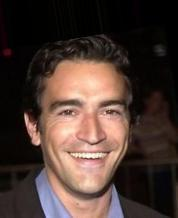

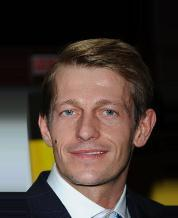

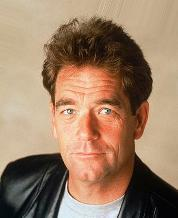

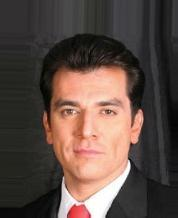

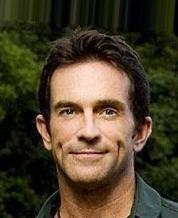

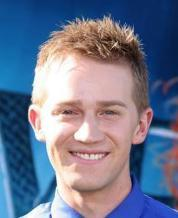

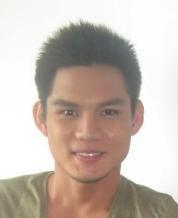

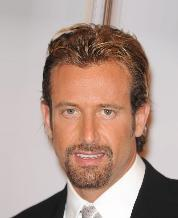

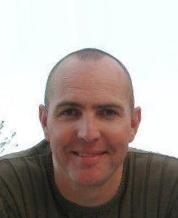

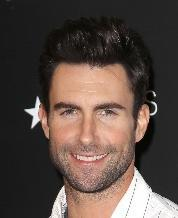

In [59]:
import os
from PIL import Image
from IPython.display import display

images_path = "/content/drive/MyDrive/Celeb_Faces"

image_files = sorted(os.listdir(images_path))

for img_name in image_files:
    img = Image.open(os.path.join(images_path, img_name))
    display(img)

In [60]:
import os
import glob
from PIL import Image


if 'experiment_type' not in globals():
    experiment_type = 'ffhq_encode'


images_dir = "/content/drive/MyDrive/Celeb_Faces"


image_paths = glob.glob(os.path.join(images_dir, '*.jpg')) + \
              glob.glob(os.path.join(images_dir, '*.png')) + \
              glob.glob(os.path.join(images_dir, '*.jpeg'))

print(f" Found {len(image_paths)} images in Drive.")


if len(image_paths) > 0:
    image_path = image_paths[0]
    original_image = Image.open(image_path).convert("RGB")
    print(f" Loaded first image: {os.path.basename(image_path)}")
else:
    raise ValueError("No images found!")

 Found 10 images in Drive.
 Loaded first image: 4.jpg


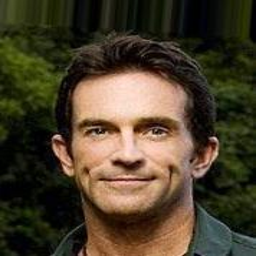

In [61]:
original_image.resize((256, 256))

### Align Image

In [62]:
!wget http://dlib.net/files/shape_predictor_68_face_landmarks.dat.bz2
!bzip2 -dk shape_predictor_68_face_landmarks.dat.bz2

--2026-02-22 11:48:36--  http://dlib.net/files/shape_predictor_68_face_landmarks.dat.bz2
Resolving dlib.net (dlib.net)... 107.180.26.78
Connecting to dlib.net (dlib.net)|107.180.26.78|:80... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://dlib.net/files/shape_predictor_68_face_landmarks.dat.bz2 [following]
--2026-02-22 11:48:37--  https://dlib.net/files/shape_predictor_68_face_landmarks.dat.bz2
Connecting to dlib.net (dlib.net)|107.180.26.78|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 64040097 (61M)
Saving to: ‘shape_predictor_68_face_landmarks.dat.bz2.1’

shape_predictor_68_ 100%[===================>]  61.07M  13.6MB/s    in 5.3s    

2026-02-22 11:48:43 (11.4 MB/s) - ‘shape_predictor_68_face_landmarks.dat.bz2.1’ saved [64040097/64040097]

bzip2: Output file shape_predictor_68_face_landmarks.dat already exists.


In [63]:
def run_alignment(image_path):
  import dlib
  from scripts.align_all_parallel import align_face
  predictor = dlib.shape_predictor("shape_predictor_68_face_landmarks.dat")
  aligned_image = align_face(filepath=image_path, predictor=predictor)
  print("Aligned image has shape: {}".format(aligned_image.size))
  return aligned_image

In [64]:

if 'experiment_type' not in globals():
    experiment_type = 'ffhq_encode'


if experiment_type not in ["celebs_sketch_to_face", "celebs_seg_to_face"]:
    input_image = run_alignment(image_path)
    print(" Image aligned successfully.")
else:
    input_image = original_image
    print("Using original image (no alignment needed).")

Aligned image has shape: (256, 256)
 Image aligned successfully.


## Step 6: Perform Inference

In [65]:
img_transforms = EXPERIMENT_ARGS['transform']
transformed_image = img_transforms(input_image)

In [66]:
def run_on_batch(inputs, net, latent_mask=None):
    if latent_mask is None:
        result_batch = net(inputs.to("cuda").float(), randomize_noise=False)
    else:
        result_batch = []
        for image_idx, input_image in enumerate(inputs):
            # get latent vector to inject into our input image
            vec_to_inject = np.random.randn(1, 512).astype('float32')
            _, latent_to_inject = net(torch.from_numpy(vec_to_inject).to("cuda"),
                                      input_code=True,
                                      return_latents=True)
            # get output image with injected style vector
            res = net(input_image.unsqueeze(0).to("cuda").float(),
                      latent_mask=latent_mask,
                      inject_latent=latent_to_inject)
            result_batch.append(res)
        result_batch = torch.cat(result_batch, dim=0)
    return result_batch

In [67]:
if experiment_type in ["celebs_sketch_to_face", "celebs_seg_to_face"]:
    latent_mask = [8, 9, 10, 11, 12, 13, 14, 15, 16, 17]
else:
    latent_mask = None

In [68]:
with torch.no_grad():
    tic = time.time()
    result_image = run_on_batch(transformed_image.unsqueeze(0), net, latent_mask)[0]
    toc = time.time()
    print('Inference took {:.4f} seconds.'.format(toc - tic))

Inference took 0.0357 seconds.


### Visualize Result

In [69]:
input_vis_image = log_input_image(transformed_image, opts)
output_image = tensor2im(result_image)

In [70]:
if experiment_type == "celebs_super_resolution":
    res = np.concatenate([np.array(input_image.resize((256, 256))),
                          np.array(input_vis_image.resize((256, 256))),
                          np.array(output_image.resize((256, 256)))], axis=1)
else:
    res = np.concatenate([np.array(input_vis_image.resize((256, 256))),
                          np.array(output_image.resize((256, 256)))], axis=1)

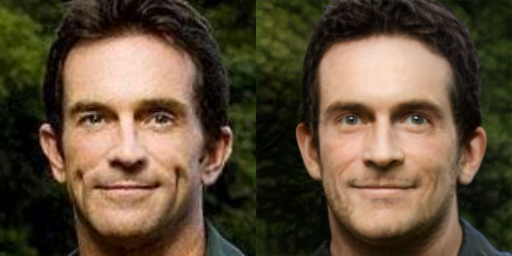

In [71]:
res_image = Image.fromarray(res)
res_image

In [72]:

import os
import glob
import numpy as np
import time
import matplotlib.pyplot as plt
from PIL import Image

images_dir = "/content/drive/MyDrive/Celeb_Faces"

# پیدا کردن همه تصاویر
image_paths = glob.glob(os.path.join(images_dir, '*.jpg')) + \
              glob.glob(os.path.join(images_dir, '*.png')) + \
              glob.glob(os.path.join(images_dir, '*.jpeg'))

image_paths = sorted(image_paths)

print(f" Found {len(image_paths)} images in Drive.")

if len(image_paths) == 0:
    raise ValueError("No images found!")


for image_path in image_paths:

    print(f"\n Processing: {os.path.basename(image_path)}")

    original_image = Image.open(image_path).convert("RGB")


    if experiment_type not in ["celebs_sketch_to_face", "celebs_seg_to_face"]:
        input_image = run_alignment(image_path)
    else:
        input_image = original_image

    transformed_image = img_transforms(input_image)

    with torch.no_grad():
        tic = time.time()
        result_image = run_on_batch(
            transformed_image.unsqueeze(0),
            net,
            latent_mask
        )[0]
        toc = time.time()

    print('Inference took {:.4f} seconds.'.format(toc - tic))

    input_vis_image = log_input_image(transformed_image, opts)
    output_image = tensor2im(result_image)





 Found 10 images in Drive.

 Processing: 1.jpg
Aligned image has shape: (256, 256)
Inference took 0.0337 seconds.

 Processing: 10.jpg
Aligned image has shape: (256, 256)
Inference took 0.0327 seconds.

 Processing: 2.jpg
Aligned image has shape: (256, 256)
Inference took 0.0347 seconds.

 Processing: 3.jpg
Aligned image has shape: (256, 256)
Inference took 0.0333 seconds.

 Processing: 4.jpg
Aligned image has shape: (256, 256)
Inference took 0.0420 seconds.

 Processing: 5.jpg
Aligned image has shape: (256, 256)
Inference took 0.0329 seconds.

 Processing: 6.jpg
Aligned image has shape: (256, 256)
Inference took 0.0336 seconds.

 Processing: 7.jpg
Aligned image has shape: (256, 256)
Inference took 0.0568 seconds.

 Processing: 8.jpg
Aligned image has shape: (256, 256)
Inference took 0.0419 seconds.

 Processing: 9.jpg
Aligned image has shape: (256, 256)
Inference took 0.0340 seconds.



 Processing: 1.jpg
Aligned image has shape: (256, 256)


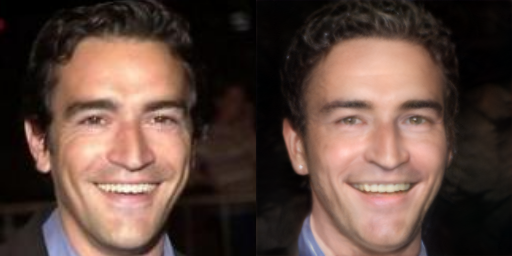


 Processing: 10.jpg
Aligned image has shape: (256, 256)


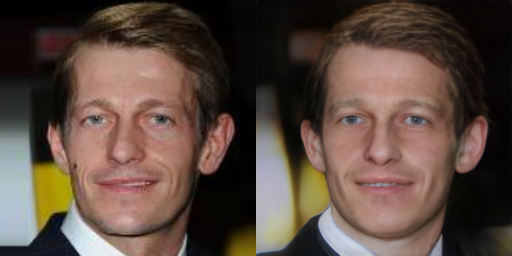


 Processing: 2.jpg
Aligned image has shape: (256, 256)


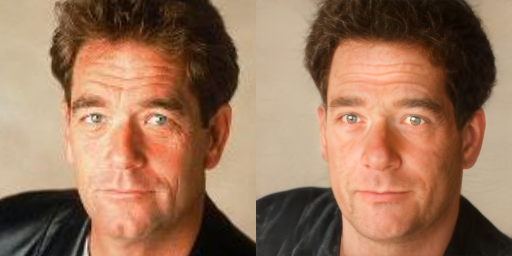


 Processing: 3.jpg
Aligned image has shape: (256, 256)


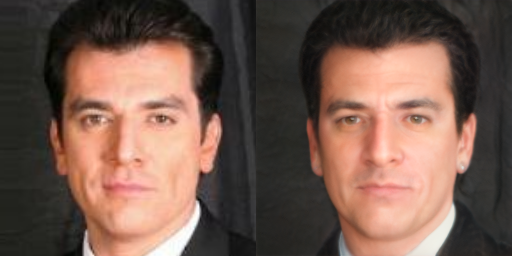


 Processing: 4.jpg
Aligned image has shape: (256, 256)


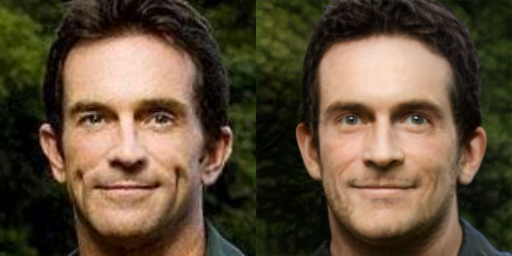


 Processing: 5.jpg
Aligned image has shape: (256, 256)


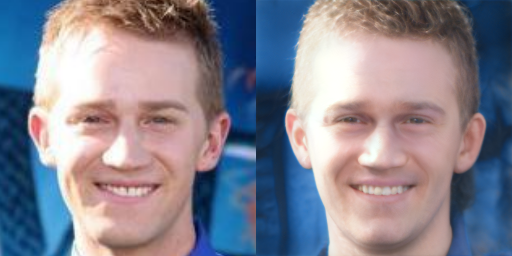


 Processing: 6.jpg
Aligned image has shape: (256, 256)


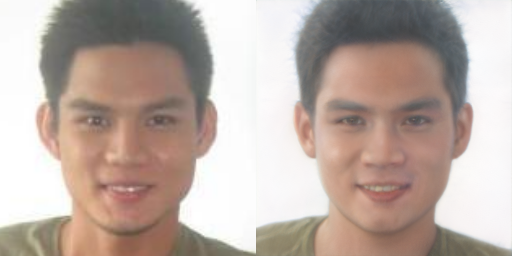


 Processing: 7.jpg
Aligned image has shape: (256, 256)


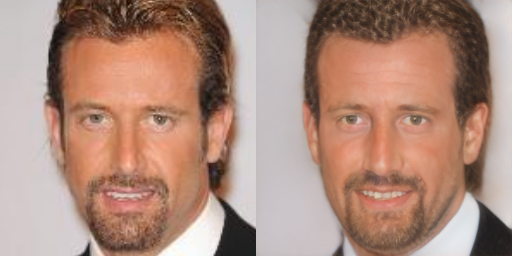


 Processing: 8.jpg
Aligned image has shape: (256, 256)


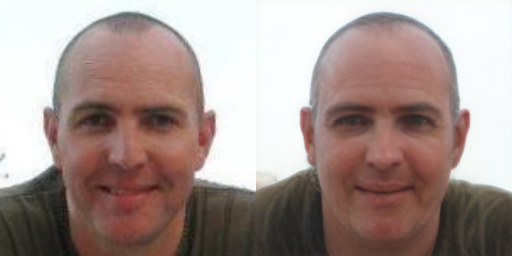


 Processing: 9.jpg
Aligned image has shape: (256, 256)


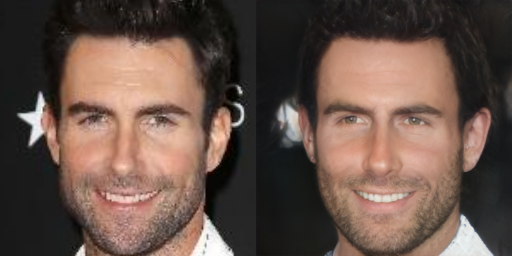

In [73]:
from IPython.display import display

for image_path in image_paths:

    print(f"\n Processing: {os.path.basename(image_path)}")

    original_image = Image.open(image_path).convert("RGB")

    if experiment_type not in ["celebs_sketch_to_face", "celebs_seg_to_face"]:
        input_image = run_alignment(image_path)
    else:
        input_image = original_image

    transformed_image = img_transforms(input_image)

    with torch.no_grad():
        result_image = run_on_batch(
            transformed_image.unsqueeze(0),
            net,
            latent_mask
        )[0]

    input_vis_image = log_input_image(transformed_image, opts)
    output_image = tensor2im(result_image)

    res = np.concatenate([
        np.array(input_vis_image.resize((256, 256))),
        np.array(output_image.resize((256, 256)))
    ], axis=1)

    res_image = Image.fromarray(res)

    display(res_image)

## Latent

Found 10 images.

Processing: 1.jpg
Aligned image has shape: (256, 256)
Inference took 0.0425 seconds.


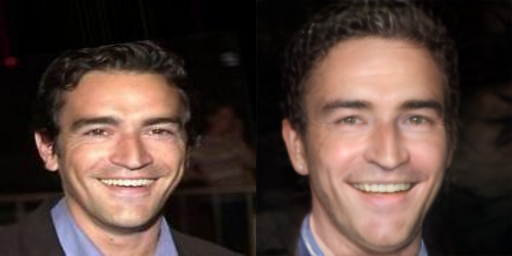


Processing: 10.jpg
Aligned image has shape: (256, 256)
Inference took 0.0361 seconds.


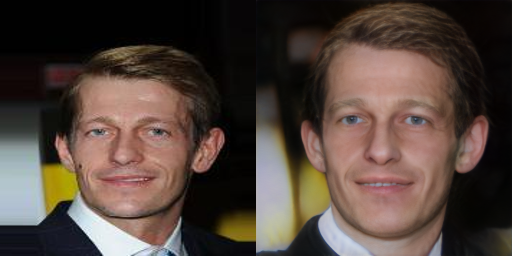


Processing: 2.jpg
Aligned image has shape: (256, 256)
Inference took 0.0386 seconds.


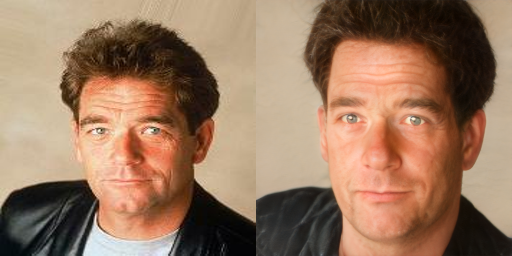


Processing: 3.jpg
Aligned image has shape: (256, 256)
Inference took 0.0396 seconds.


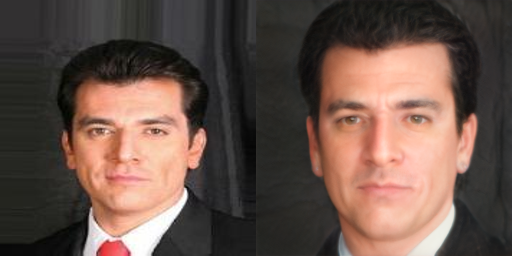


Processing: 4.jpg
Aligned image has shape: (256, 256)
Inference took 0.0335 seconds.


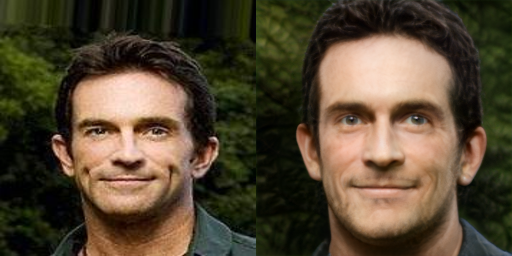


Processing: 5.jpg
Aligned image has shape: (256, 256)
Inference took 0.0370 seconds.


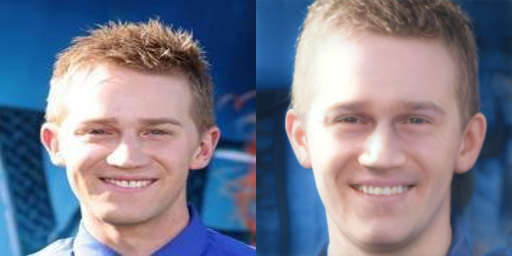


Processing: 6.jpg
Aligned image has shape: (256, 256)
Inference took 0.0344 seconds.


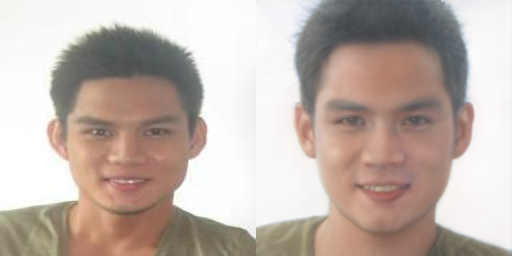


Processing: 7.jpg
Aligned image has shape: (256, 256)
Inference took 0.0336 seconds.


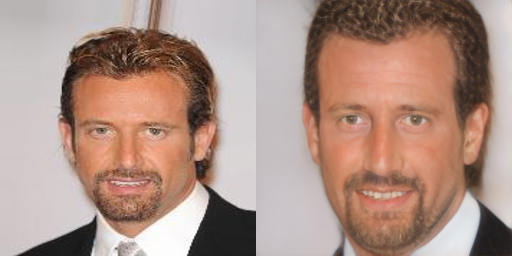


Processing: 8.jpg
Aligned image has shape: (256, 256)
Inference took 0.0344 seconds.


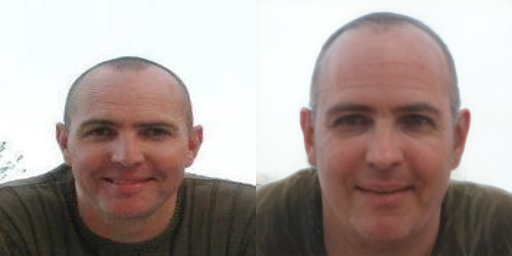


Processing: 9.jpg
Aligned image has shape: (256, 256)
Inference took 0.0444 seconds.


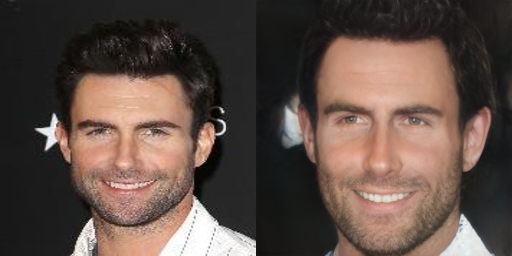


 All latents extracted successfully.


In [74]:
import os
import glob
import numpy as np
import torch
import time
from PIL import Image
from IPython.display import display

images_dir = "/content/drive/MyDrive/Celeb_Faces"

# پیدا کردن تصاویر
image_paths = glob.glob(os.path.join(images_dir, '*.jpg')) + \
              glob.glob(os.path.join(images_dir, '*.png')) + \
              glob.glob(os.path.join(images_dir, '*.jpeg'))

image_paths = sorted(image_paths)

print(f"Found {len(image_paths)} images.")

if len(image_paths) == 0:
    raise ValueError("No images found!")

# دیکشنری برای ذخیره latent ها
latents_dict = {}

for image_path in image_paths:

    print(f"\nProcessing: {os.path.basename(image_path)}")

    # Load image
    original_image = Image.open(image_path).convert("RGB")

    # Align image
    input_image = run_alignment(image_path)

    # Transform
    transformed_image = img_transforms(input_image)

    # Encode → گرفتن latent
    with torch.no_grad():
        tic = time.time()
        reconstruction, latent = net(
            transformed_image.unsqueeze(0).cuda(),
            return_latents=True
        )
        toc = time.time()

    print(f"Inference took {toc - tic:.4f} seconds.")

    # ذخیره latent برای استفاده بعدی
    latents_dict[os.path.basename(image_path)] = latent.clone()

    # تبدیل به تصویر قابل نمایش
    reconstruction_img = tensor2im(reconstruction[0])

    # نمایش original و reconstruction کنار هم
    combined = np.concatenate([
        np.array(original_image.resize((256,256))),
        np.array(reconstruction_img.resize((256,256)))
    ], axis=1)

    display(Image.fromarray(combined))

print("\n All latents extracted successfully.")

In [75]:
!wget https://raw.githubusercontent.com/genforce/interfacegan/master/boundaries/stylegan_ffhq_age_boundary.npy -O age.npy

--2026-02-22 11:49:59--  https://raw.githubusercontent.com/genforce/interfacegan/master/boundaries/stylegan_ffhq_age_boundary.npy
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4224 (4.1K) [application/octet-stream]
Saving to: ‘age.npy’

age.npy             100%[===================>]   4.12K  --.-KB/s    in 0s      

2026-02-22 11:49:59 (64.3 MB/s) - ‘age.npy’ saved [4224/4224]



In [76]:
import numpy as np
import torch

# load boundary
age_direction = np.load("age.npy")  # (1, 512)

age_direction = torch.from_numpy(age_direction).float().cuda()

# تبدیل به W+
age_direction = age_direction.unsqueeze(1).repeat(1, 18, 1)

print("Final age direction shape:", age_direction.shape)

Final age direction shape: torch.Size([1, 18, 512])



Age Editing: 1.jpg


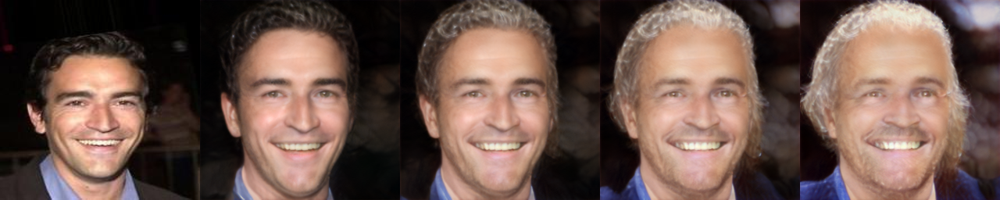


Age Editing: 10.jpg


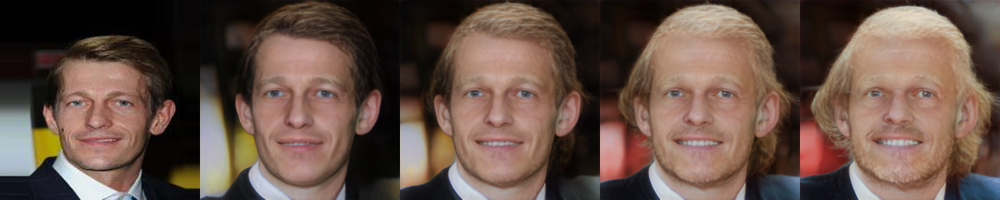


Age Editing: 2.jpg


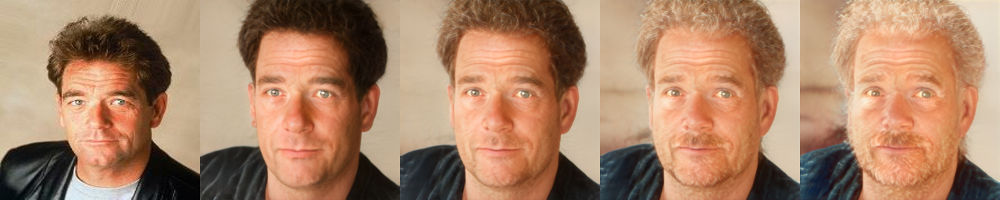


Age Editing: 3.jpg


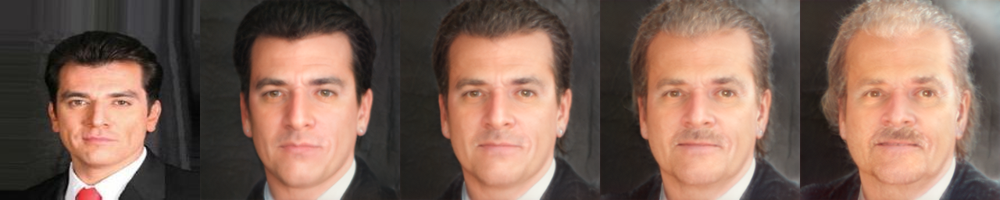


Age Editing: 4.jpg


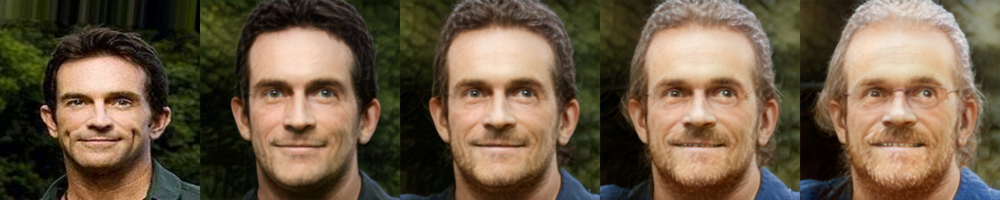


Age Editing: 5.jpg


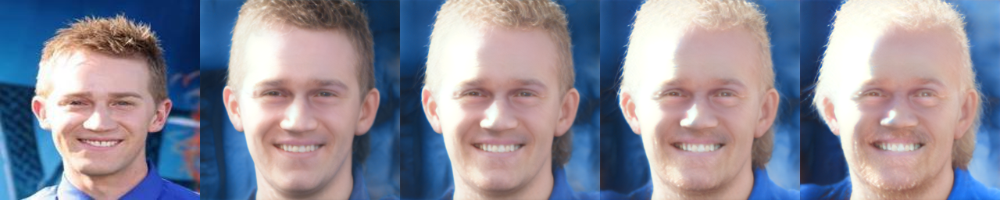


Age Editing: 6.jpg


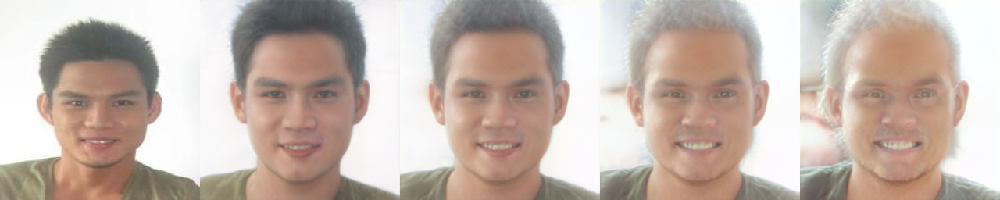


Age Editing: 7.jpg


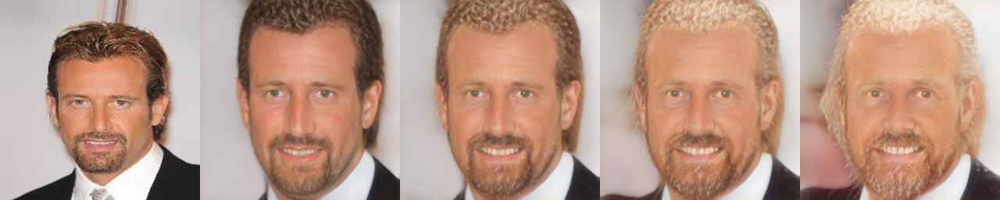


Age Editing: 8.jpg


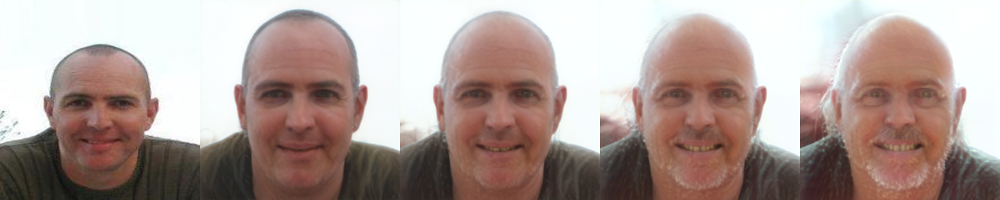


Age Editing: 9.jpg


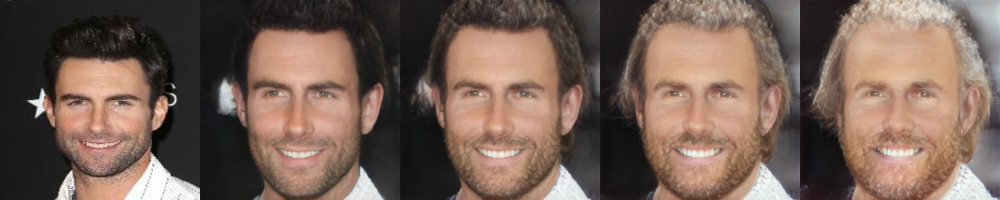

In [77]:
from IPython.display import display

alpha_values = [5, 10, 15]  # شدت افزایش سن

for image_name, latent in latents_dict.items():

    print(f"\nAge Editing: {image_name}")

    results = []

    # original
    original_path = os.path.join(images_dir, image_name)
    original_image = Image.open(original_path).convert("RGB")
    results.append(original_image)

    # reconstruction
    with torch.no_grad():
        reconstruction, _ = net.decoder([latent], input_is_latent=True)
    reconstruction_img = tensor2im(reconstruction[0])
    results.append(reconstruction_img)

    # age editing
    for alpha in alpha_values:

        new_latent = latent + alpha * age_direction


        with torch.no_grad():
            aged_img, _ = net.decoder(
                [new_latent],
                input_is_latent=True,
                randomize_noise=False
            )

        aged_img = tensor2im(aged_img[0])
        results.append(aged_img)

    # نمایش کنار هم
    combined = np.concatenate(
        [np.array(img.resize((256,256))) for img in results],
        axis=1
    )

    display(Image.fromarray(combined))